## 67. Four-window detached feedback rollout training (LiDAR/IMU SO(3))
This standalone notebook extends Notebook 66 to train on four chronological 5-second windows per sample. The model predicts a correction at each window, then its detached corrected rotation becomes the prior for the next window. It receives direct ground-truth rotation supervision at every step. There is no paired loss, path-point interpolation, consistency loss, explicit progress penalty, or extra exact-zero sampling.

Memory contract: perform four separate forwards/backwards, with one optimizer step after all four. Intermediate rotations are detach()ed; gradients do not propagate across time. This is detached-feedback / stop-gradient rollout training, not full truncated BPTT through earlier predictions.

Physical-data contract: the true-calibration augmentation is drawn once per trajectory group and replayed with the same RNG seed for every consecutive window. The notebook asserts identical physical calibration targets across all four windows. The initial fine/coarse fault is sampled once, and updates modify rotations only; translation/time offset remain unchanged in propagation.

The model, KAIST dataset splits, PooledCalibrationModel architecture, 3D rotation-vector heads, and checkpoint API are inherited from Notebook 66. Run the cells sequentially; no previous notebook state is needed.

In [2]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the nn-obs-calib repository root containing src/obscalib.")

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch
from obscalib.geometry.lie import se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint
from obscalib.training.metrics_logger import MetricsLogger

print("Repository root:", ROOT)
print("PyTorch:", torch.__version__)

from torch.utils.data import Dataset, DataLoader
from obscalib.geometry.lie import so3_exp, se3_exp
import copy
import random
import pandas as pd


Repository root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
PyTorch: 2.7.1+cu126


In [52]:
RUN_NAME = 'kaist_large_paired_003.4_4step_rollout'

RANDOM_SEED = 12345
TRAIN_PAIR_SEED, VALIDATION_PAIR_SEED, TEST_PAIR_SEED = 23456, 34567, 45678
VISUALIZATION_PAIR_SEED = 56789
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_DTYPE = torch.float32

CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')
CALIBRATION_CONTEXT_DIM = 7
KAIST_TAU_IMU_S, KAIST_TAU_LIDAR_S, KAIST_TAU_LIDAR_RIGHT_S = 0.0, -0.025, -0.035
REFINED_TAU_BY_SENSOR_S = {'imu': KAIST_TAU_IMU_S, 'lidar': KAIST_TAU_LIDAR_S, 'lidar_right': KAIST_TAU_LIDAR_RIGHT_S}

WINDOW_DURATION_S, WINDOW_STRIDE_S, MAX_SAMPLES_PER_SENSOR = 5.0, 5.0, 700
BATCH_SIZE, NUM_WORKERS, DROP_LAST_TRAIN = 16, 0, True  # Each item includes FOUR consecutive windows.
NUM_EPOCHS, LEARNING_RATE, WEIGHT_DECAY, GRADIENT_CLIP_NORM = 100, 2e-5, 1e-4, 1.0
CHECKPOINT_EVERY_EPOCHS, PRINT_EVERY_BATCHES = 3, 500
LR_REDUCTION_FACTOR, LR_PATIENCE_EPOCHS = 0.5, 10

MEASUREMENT_DIM, TOKEN_INPUT_DIM = 6, 8
D_MODEL, N_HEADS, NUM_TRANSFORMER_LAYERS, DIM_FEEDFORWARD = 128, 8, 12, 512
TRANSFORMER_DROPOUT, NUM_SUMMARY_TOKENS = 0.0, 1
POOLER_N_HEADS, POOLER_DROPOUT = 8, 0.0
MLP_HIDDEN_DIMS, SHARED_FEATURE_DIM, MLP_DROPOUT = (256, 128), 128, 0.0
HEAD_HIDDEN_DIMS, HEAD_DROPOUT = (128, 64), 0.0

# Original Notebook 58-style rotation/translation/time distributions.
FINE_ROTATION_MAX_DEG, FINE_ROTATION_SCALE_DEG = 60.0, 30.0
COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG = 60.0, 179.0
COARSE_PRIOR_PROBABILITY = 0.50                 # Set 0.80 and min=120 to reproduce Notebook 58's angle mix.
STUDENT_T_DOF = 3.0
PRIOR_TRANSLATION_MAX_M, PRIOR_TRANSLATION_SCALE_M = 0.05, 0.02
# PRIOR_TAU_MAX_S, PRIOR_TAU_SCALE_S = 0.50, 0.25
PRIOR_TAU_MAX_S, PRIOR_TAU_SCALE_S = 0.001, 0.0005
# TRUE_CALIBRATION_ROTATION_MAX_DEG, TRUE_CALIBRATION_TAU_MAX_S = 180.0, 0.030
TRUE_CALIBRATION_ROTATION_MAX_DEG, TRUE_CALIBRATION_TAU_MAX_S = 180.0, 0.001

# Direct GT supervision. All three rotation terms are separately logged and weighted.
CORRECTION_LOSS_TYPE = 'mse'
ROTATION_SUPERVISION_MODE = 'so3'               # Used only by historical +/-pair evaluation helpers.
ROTATION_LOSS_SCALE_RAD = np.deg2rad(60.0)
ROTATION_GEODESIC_WEIGHT = 1.0                 # Set to 0 for pure direction+magnitude ablation.
ROTATION_DIRECTION_WEIGHT = 0.0                # Angular-axis alignment, 1 - cosine.
ROTATION_MAGNITUDE_WEIGHT = 0.0                # Squared normalized magnitude error.
ROTATION_DIRECTION_MIN_TARGET_DEG = 1.0        # Axis is meaningless near an exact zero correction.
ROTATION_DIRECTION_EPS_RAD = 1e-3              # Stable normalization near a zero predicted vector.
ACTIVE_ROTATION_WEIGHT = 1.0                  # Rotation regression for faulted examples.
HEALTHY_ROTATION_WEIGHT = 0.1                 # Preserve low drift from unperturbed sensors.
TRANSLATION_LOSS_SCALE_M, TIME_OFFSET_LOSS_SCALE_S = 0.05, 0.05
ROTATION_LOSS_WEIGHT, TRANSLATION_LOSS_WEIGHT, TIME_OFFSET_LOSS_WEIGHT = 2.0, 0.0, 0.0

# One initial fine/coarse fault per four-window trajectory. No path points.

# Stochastic and full runs both use the same weights loaded during model construction.
RUN_STOCHASTIC_ROLLOUT_TEST = True
RUN_FULL_TRAINING = True                   # Enable after inspecting the reversible stochastic diagnostic.
REQUIRE_STOCHASTIC_GATE = False

# Select exactly one initialization mode:
#   'scratch': new random model, epoch 0, new AdamW/scheduler.
#   'weights': load MODEL weights only from another run, epoch 0, new AdamW/scheduler.
#   'resume': restore model + AdamW + scheduler + epoch + RNG from this run's last.pt.
INITIALIZATION_MODE = 'weights'   # 'scratch', 'weights', or 'resume'
# INITIAL_WEIGHTS_CHECKPOINT = ROOT / 'runs' / 'kaist_large_paired_003.3_3d_large' / 'best.pt'
INITIAL_WEIGHTS_CHECKPOINT = ROOT / 'runs' / 'kaist_large_paired_003.3_3d_direction_magnitude' / 'best.pt'
RESUME_CHECKPOINT = ROOT / 'runs' / RUN_NAME / 'last.pt'
# In 'weights' mode, use a NEW RUN_NAME so the source checkpoint cannot be overwritten.

assert 0 < FINE_ROTATION_MAX_DEG <= COARSE_ROTATION_MIN_DEG < COARSE_ROTATION_MAX_DEG < 180
assert 0 <= COARSE_PRIOR_PROBABILITY <= 1
assert len(CALIBRATION_KEYS) == 3
assert ROTATION_GEODESIC_WEIGHT >= 0 and ROTATION_DIRECTION_WEIGHT >= 0 and ROTATION_MAGNITUDE_WEIGHT >= 0
assert ROTATION_GEODESIC_WEIGHT + ROTATION_DIRECTION_WEIGHT + ROTATION_MAGNITUDE_WEIGHT > 0
assert HEALTHY_ROTATION_WEIGHT > 0 and ACTIVE_ROTATION_WEIGHT > 0
print('Rotation component weights: geo=', ROTATION_GEODESIC_WEIGHT, 'dir=', ROTATION_DIRECTION_WEIGHT, 'mag=', ROTATION_MAGNITUDE_WEIGHT)

if INITIALIZATION_MODE not in ('scratch', 'weights', 'resume'):
    raise ValueError(f'Unknown INITIALIZATION_MODE={INITIALIZATION_MODE!r}')

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
if DEVICE.type == 'cuda':
    torch.cuda.manual_seed_all(RANDOM_SEED)
print('Device:', DEVICE, '| keys:', CALIBRATION_KEYS)
print('Fine Student-t:', (0, FINE_ROTATION_MAX_DEG), 'scale', FINE_ROTATION_SCALE_DEG, 'coarse uniform:', (COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG), 'p:', COARSE_PRIOR_PROBABILITY)
print('Reference KAIST tau [ms]:', {k: 1000 * v for k, v in REFINED_TAU_BY_SENSOR_S.items()})
print('Initialization:', INITIALIZATION_MODE, '| checkpoint:', {'scratch': None, 'weights': INITIAL_WEIGHTS_CHECKPOINT, 'resume': RESUME_CHECKPOINT}[INITIALIZATION_MODE])


# Four-step training parameters.
ROLLOUT_NUM_STEPS = 4
ROLLOUT_START_STRIDE_TRAIN = 4          # Nonoverlapping 4-window sequences; change to 1 for overlapping starts.
ROLLOUT_START_STRIDE_VAL = 4
ROLLOUT_UPDATE_ALL_KEYS = True         # Apply predicted rotations to healthy sensors too; their drift is supervised.
ROLLOUT_INITIAL_FAULT_WEIGHTING = True # Keep the initially faulty sensor at ACTIVE_ROTATION_WEIGHT even as error shrinks.
ROLLOUT_STEP_LOSS_WEIGHTS = (1.0, 1.0, 1.0, 1.0)
ROLLOUT_SELECTION_METRIC = 'final_fault_residual_deg'  # Select checkpoints by end-of-rollout physical SO(3) error.

STOCHASTIC_ROLLOUT_NUM_TRAIN_TRAJECTORIES = 4
STOCHASTIC_ROLLOUT_NUM_VAL_TRAJECTORIES = 4
STOCHASTIC_ROLLOUT_NUM_STEPS = 300
STOCHASTIC_ROLLOUT_PRINT_EVERY = 25

assert ROLLOUT_NUM_STEPS == 4, 'This notebook documents a four-window rollout; adapt weights and plots if changing it.'
assert len(ROLLOUT_STEP_LOSS_WEIGHTS) == ROLLOUT_NUM_STEPS
assert all(value >= 0 for value in ROLLOUT_STEP_LOSS_WEIGHTS) and sum(ROLLOUT_STEP_LOSS_WEIGHTS) > 0
print('Rollout:', ROLLOUT_NUM_STEPS, 'consecutive windows, detached feedback, update all sensors:', ROLLOUT_UPDATE_ALL_KEYS)
print('Starting model checkpoint:', INITIAL_WEIGHTS_CHECKPOINT)


Rotation component weights: geo= 1.0 dir= 0.0 mag= 0.0
Device: cuda | keys: ('imu', 'lidar', 'lidar_right')
Fine Student-t: (0, 60.0) scale 30.0 coarse uniform: (60.0, 179.0) p: 0.5
Reference KAIST tau [ms]: {'imu': 0.0, 'lidar': -25.0, 'lidar_right': -35.0}
Initialization: weights | checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_large_paired_003.3_3d_direction_magnitude/best.pt
Rollout: 4 consecutive windows, detached feedback, update all sensors: True
Starting model checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_large_paired_003.3_3d_direction_magnitude/best.pt


In [37]:
KAIST_DATASET_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset')
LIDAR_POSE_ROOT = Path('/home/camel/Skoltech/phd_proposal/data/KAISTDataset')

TRAIN_NAMES = ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
VAL_NAMES = ['Urban26', 'Urban28']
TEST_NAMES = ['Urban38', 'Urban39']
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES
if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError('Train, validation and test sequences overlap.')

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)
T_B_L_right = np.array([
    [-0.512152, 0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109, 1.91294],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)
T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(
    T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, T_B_L_right=T_B_L_right,
    tau_imu_s=KAIST_TAU_IMU_S, tau_lidar_s=KAIST_TAU_LIDAR_S, tau_lidar_right_s=KAIST_TAU_LIDAR_RIGHT_S,
)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
print('Sequences:', TRAIN_NAMES, VAL_NAMES, TEST_NAMES)
print('Reference offsets [ms]:', {key: 1000 * value for key, value in REFINED_TAU_BY_SENSOR_S.items()})


Sequences: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16'] ['Urban26', 'Urban28'] ['Urban38', 'Urban39']
Reference offsets [ms]: {'imu': 0.0, 'lidar': -25.0, 'lidar_right': -35.0}


In [23]:
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename='lidar_map_poses_vlp_right.csv')
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f'Required right LiDAR odometry missing for {spec.name}: {spec.lidar_right_pose_csv}')
spec_by_name = {spec.name: spec for spec in all_specs}

def make_dataset_65(names, rig):
    return KAISTCalibrationDataset([spec_by_name[name] for name in names], rig, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

train_dataset = make_dataset_65(TRAIN_NAMES, rig_calibration)
val_dataset = make_dataset_65(VAL_NAMES, rig_calibration)
test_dataset = make_dataset_65(TEST_NAMES, rig_calibration)

for split_name, dataset in (('train', train_dataset), ('validation', val_dataset), ('test', test_dataset)):
    if tuple(dataset.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f'{split_name} keys: {tuple(dataset.calibration_keys)} != {CALIBRATION_KEYS}')
    sample = collate_windows([dataset[0]])
    for key, expected in REFINED_TAU_BY_SENSOR_S.items():
        actual = float(sample.current_calibration[key].time_offset.reshape(-1)[0].item())
        assert abs(actual - expected) < 2e-6, f'{split_name}/{key}: expected {expected}, got {actual}'
    print(dataset.summary())

# Like Notebook 58: reference tau must not silently shift raw measurements or timestamps.
zero_clock_rig = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, T_B_L_right=T_B_L_right, tau_imu_s=0.0, tau_lidar_s=0.0, tau_lidar_right_s=0.0)
zero_clock_control = make_dataset_65([VAL_NAMES[0]], zero_clock_rig)
corrected_clock_control = make_dataset_65([VAL_NAMES[0]], rig_calibration)
if len(zero_clock_control) != len(corrected_clock_control):
    raise AssertionError('Changing reference tau changed the number of windows.')
for index in sorted({0, len(zero_clock_control) // 2, len(zero_clock_control) - 1}):
    original, corrected = zero_clock_control[index], corrected_clock_control[index]
    for stream_name, original_stream in original.streams.items():
        new_stream = corrected.streams[stream_name]
        torch.testing.assert_close(original_stream.values, new_stream.values)
        torch.testing.assert_close(original_stream.timestamps, new_stream.timestamps)
        if original_stream.interval_start_timestamps is not None:
            torch.testing.assert_close(original_stream.interval_start_timestamps, new_stream.interval_start_timestamps)
print('KAIST temporal reference check: corrected τ targets, raw measurements and timestamps unchanged.')


KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704
KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658
KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiDAR

## 4. Chronological sequence sampler
Each training item is a tuple of indices from one KAIST sequence; no shuffle can mix windows from different sequences or change their order inside a trajectory. Shuffle acts only on the trajectory-start groups. A stride of four avoids near-duplicate training examples.

In [38]:
class SequenceRolloutStarts(Dataset):
    """Return indices for chronological, same-sequence groups of consecutive windows."""

    def __init__(self, base_dataset, sequence_names, num_steps=4, stride=4):
        if num_steps < 1 or stride < 1:
            raise ValueError('num_steps and stride must be positive')
        self.base_dataset = base_dataset
        self.num_steps = int(num_steps)
        self.starts = []
        self.sequence_counts = {}
        for sequence_name in sequence_names:
            indices = [int(index) for index in base_dataset.window_indices_for_sequence(sequence_name)]
            if len(indices) != len(set(indices)):
                raise ValueError(f'Duplicate window indices in {sequence_name}')
            sequence_starts = [tuple(indices[i:i + num_steps]) for i in range(0, len(indices) - num_steps + 1, stride)]
            self.sequence_counts[sequence_name] = len(sequence_starts)
            self.starts.extend(sequence_starts)
        if not self.starts:
            raise ValueError('No chronological rollout groups were constructed')

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, index):
        return torch.tensor(self.starts[index], dtype=torch.int64)


def make_rollout_raw_windows(base_dataset, start_indices):
    """Collate the same B trajectories at consecutive timesteps, moving only one batch at a time."""
    matrix = torch.as_tensor(start_indices, dtype=torch.int64).cpu()
    if matrix.ndim != 2 or matrix.shape[1] != ROLLOUT_NUM_STEPS:
        raise ValueError(f'Expected [B, {ROLLOUT_NUM_STEPS}] indices, got {tuple(matrix.shape)}')
    return [window_batch_to(collate_windows([base_dataset[int(index)] for index in matrix[:, step]]), DEVICE, dtype=MODEL_DTYPE)
            for step in range(ROLLOUT_NUM_STEPS)]


rollout_train_starts = SequenceRolloutStarts(train_dataset, TRAIN_NAMES, ROLLOUT_NUM_STEPS, ROLLOUT_START_STRIDE_TRAIN)
rollout_val_starts = SequenceRolloutStarts(val_dataset, VAL_NAMES, ROLLOUT_NUM_STEPS, ROLLOUT_START_STRIDE_VAL)
rollout_test_starts = SequenceRolloutStarts(test_dataset, TEST_NAMES, ROLLOUT_NUM_STEPS, ROLLOUT_START_STRIDE_VAL)
train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
rollout_train_loader = DataLoader(rollout_train_starts, batch_size=BATCH_SIZE, shuffle=True, drop_last=DROP_LAST_TRAIN, num_workers=0, generator=train_shuffle_generator)
rollout_val_loader = DataLoader(rollout_val_starts, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=0)
rollout_test_loader = DataLoader(rollout_test_starts, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=0)
for name, dataset, loader in (('train', rollout_train_starts, rollout_train_loader), ('val', rollout_val_starts, rollout_val_loader), ('test', rollout_test_starts, rollout_test_loader)):
    print(f'{name}: {len(dataset)} trajectory groups, {len(loader)} batches | by sequence: {dataset.sequence_counts}')
print('First train group indices:', rollout_train_starts[0].tolist())


train: 499 trajectory groups, 31 batches | by sequence: {'Urban08': 14, 'Urban12': 118, 'Urban13': 55, 'Urban14': 71, 'Urban15': 46, 'Urban16': 195}
val: 104 trajectory groups, 7 batches | by sequence: {'Urban26': 23, 'Urban28': 81}
test: 174 trajectory groups, 11 batches | by sequence: {'Urban38': 87, 'Urban39': 87}
First train group indices: [0, 1, 2, 3]


## 5. Physical augmentation and mixed-angle fault sampler

In [39]:
from obscalib.augmentations.config import PerturbationDistribution, SensorTopologyAugmentationConfig, CommonBodyFrameRandomizationConfig

# Physical measurements are identical across all points of each geodesic path.
# Keep the raw timestamps and noise model unchanged; only prior calibration varies.
context_augmentation_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True, probability=1.0, rotation_probability=1.0, translation_probability=0.0,
        time_offset_probability=1.0,
        rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(TRUE_CALIBRATION_ROTATION_MAX_DEG)),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_TAU_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)

def prior_config_65(*, rotation_min_deg, rotation_max_deg, distribution, rotation_scale_deg=None):
    kwargs = {'minimum': np.deg2rad(rotation_min_deg), 'maximum': np.deg2rad(rotation_max_deg), 'distribution': distribution}
    if distribution == PerturbationDistribution.TRUNCATED_STUDENT_T:
        kwargs.update(scale=np.deg2rad(rotation_scale_deg), degrees_of_freedom=int(STUDENT_T_DOF))
    return PriorPerturbationConfig(
        enabled=True, probability=1.0, rotation=PerturbationMagnitudeConfig(**kwargs),
        translation=PerturbationMagnitudeConfig(maximum=PRIOR_TRANSLATION_MAX_M, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=PRIOR_TRANSLATION_SCALE_M, degrees_of_freedom=int(STUDENT_T_DOF)),
        time_offset=PerturbationMagnitudeConfig(maximum=PRIOR_TAU_MAX_S, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=PRIOR_TAU_SCALE_S, degrees_of_freedom=int(STUDENT_T_DOF)),
        one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
    )

fine_prior_config = prior_config_65(rotation_min_deg=0.0, rotation_max_deg=FINE_ROTATION_MAX_DEG, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, rotation_scale_deg=FINE_ROTATION_SCALE_DEG)
coarse_prior_config = prior_config_65(rotation_min_deg=COARSE_ROTATION_MIN_DEG, rotation_max_deg=COARSE_ROTATION_MAX_DEG, distribution=PerturbationDistribution.UNIFORM)
context_augmentation_pipeline = AugmentationPipeline(context_augmentation_config)
fine_prior_perturber = CalibrationPriorPerturber(fine_prior_config)
coarse_prior_perturber = CalibrationPriorPerturber(coarse_prior_config)

from obscalib.augmentations.sampling import sample_perturbation_magnitudes
sampling_generator = torch.Generator(device=DEVICE.type).manual_seed(TRAIN_PAIR_SEED + 700001)
for kind, cfg, lo, hi in (
    ('fine', fine_prior_config.rotation, 0.0, FINE_ROTATION_MAX_DEG),
    ('coarse', coarse_prior_config.rotation, COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG),
):
    mags = torch.rad2deg(sample_perturbation_magnitudes(cfg, 4096, device=DEVICE, dtype=MODEL_DTYPE, generator=sampling_generator)).reshape(-1)
    assert bool(((mags >= lo - 1e-3) & (mags <= hi + 1e-3)).all()), f'{kind} magnitudes outside configured interval: {mags.min()} .. {mags.max()}'
    print(f'{kind} sampled magnitudes [deg]: min={mags.min().item():.3f}, median={mags.median().item():.3f}, max={mags.max().item():.3f}')
print('Mixed-angle initial faults; one shared true-calibration augmentation per trajectory; no artificial measurement noise.')


fine sampled magnitudes [deg]: min=0.009, median=18.804, max=59.999
coarse sampled magnitudes [deg]: min=60.016, median=120.029, max=178.981
Mixed-angle initial faults; one shared true-calibration augmentation per trajectory; no artificial measurement noise.


## 6. Identical pooled 3D model and warm-start checkpoint

In [40]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation="gelu"),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation="gelu", dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(
        n_heads=POOLER_N_HEADS,
        dropout=POOLER_DROPOUT,
        calibration_context_dim=0,           # CALIBRATION_CONTEXT_DIM
    ),

    head=PooledCalibrationHeadConfig(
        calibration_context_dim=0,
        hidden_dims=HEAD_HIDDEN_DIMS,
        activation="gelu",
        dropout=HEAD_DROPOUT,
    ),
)

geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)
model = PooledCalibrationModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
# Load the starting weights HERE, before the stochastic diagnostic and smoke tests.
# Loading only `model` never restores optimizer, scheduler, epoch or RNG.
initial_checkpoint_path = None
if INITIALIZATION_MODE == 'weights':
    initial_checkpoint_path = Path(INITIAL_WEIGHTS_CHECKPOINT)
elif INITIALIZATION_MODE == 'resume':
    initial_checkpoint_path = Path(RESUME_CHECKPOINT)

if initial_checkpoint_path is not None:
    if not initial_checkpoint_path.is_file():
        raise FileNotFoundError(f'{INITIALIZATION_MODE} checkpoint not found: {initial_checkpoint_path}')
    load_training_checkpoint(initial_checkpoint_path, model=model, map_location=DEVICE, restore_rng_state=False)
    print(f'Loaded initial model weights ({INITIALIZATION_MODE}): {initial_checkpoint_path}')
else:
    print('Model initialized from scratch (random weights).')

calibration_updater = CalibrationUpdater()
window_step = WindowStep(geometry_processor=geometry_processor, tokenizer=tokenizer, model=model, calibration_updater=calibration_updater)

# if not getattr(model, "uses_calibration_context", False):
#     raise RuntimeError("This experiment requires the pooled model to use numeric calibration context.")

print(model)
print()
print("Parameters:", sum(parameter.numel() for parameter in model.parameters()))
print("Trainable parameters:", sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad))
print("Pooler calibration context dim:", model.pooler.calibration_context_dim)
print("Head calibration context dim:", model.head.config.calibration_context_dim)


Loaded initial model weights (weights): /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_large_paired_003.3_3d_direction_magnitude/best.pt
PooledCalibrationModel(
  (transformer_encoder): SummaryTokenTransformerEncoder(
    (input_projection): Linear(in_features=8, out_features=128, bias=True)
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-11): 12 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
          )
          (linear1): Linear(in_features=128, out_features=512, bias=True)
          (dropout): Dropout(p=0.0, inplace=False)
          (linear2): Linear(in_features=512, out_features=128, bias=True)
          (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.0, inplace=False)
          (dropout2): Drop

## 7. Four-step physical rollout construction
Important: physical augmentation generator is seeded identically for all four steps. If data-dependent RNG consumption causes it to generate inconsistent calibrations, the following assertions will fail rather than silently train on moving targets. The initial prior is sampled exactly once for the group.

In [41]:
def make_augmentation_generator(seed: int):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))


def clone_window_with_calibration(window: WindowBatch, calibration):
    return WindowBatch(streams=dict(window.streams), current_calibration=calibration, metadata=dict(window.metadata), targets=None if window.targets is None else dict(window.targets), dataset_indices=window.dataset_indices)


def sample_mixed_prior_65(true_calibration, *, generator, coarse_probability=None):
    """Sample 50/50 fine/coarse fault magnitudes per example; each perturbation uses a uniformly sampled axis."""
    coarse_probability = COARSE_PRIOR_PROBABILITY if coarse_probability is None else float(coarse_probability)
    if not 0 <= coarse_probability <= 1:
        raise ValueError(f'Invalid coarse probability: {coarse_probability}')
    _, fine_xi, fine_tau = fine_prior_perturber(true_calibration, generator=generator)
    _, coarse_xi, coarse_tau = coarse_prior_perturber(true_calibration, generator=generator)
    state = next(iter(true_calibration.values()))
    B = state.transform.shape[0]
    coarse_mask = torch.rand(B, device=state.transform.device, generator=generator) < coarse_probability
    delta_xi = {key: torch.where(coarse_mask[:, None], coarse_xi[key], fine_xi[key]) for key in true_calibration}
    delta_tau = {key: torch.where(coarse_mask[:, None], coarse_tau[key], fine_tau[key]) for key in true_calibration}
    return delta_xi, delta_tau, coarse_mask


def correction_target(window: WindowBatch, calibration_key):
    if window.targets is None:
        raise ValueError('Window has no calibration targets.')
    target = window.targets[calibration_key]
    current_state = window.current_calibration[calibration_key]
    if target.next_transform is None or target.next_time_offset is None:
        raise ValueError(f'Calibration target {calibration_key!r} does not contain the final calibration state.')
    target_delta_transform = target.next_transform @ torch.linalg.inv(current_state.transform)
    target_delta_xi = se3_log(target_delta_transform)
    target_delta_tau = target.next_time_offset - current_state.time_offset
    return target_delta_xi, target_delta_tau


In [42]:
def copy_calibration_states(states):
    return {key: CalibrationState(transform=state.transform.detach().clone(), time_offset=state.time_offset.detach().clone())
            for key, state in states.items()}


def prepare_rollout_case(raw_windows, *, physical_seed: int, fault_generator, coarse_probability=None):
    """Share one physical scene/rig truth over time and perturb its initial prior ONCE."""
    if len(raw_windows) != ROLLOUT_NUM_STEPS:
        raise ValueError('Wrong number of physical windows')
    physical_windows = [context_augmentation_pipeline(raw, generator=make_augmentation_generator(physical_seed)).augmented_window
                        for raw in raw_windows]
    reference_truth = physical_windows[0].current_calibration
    for step, window in enumerate(physical_windows):
        for key in CALIBRATION_KEYS:
            torch.testing.assert_close(window.current_calibration[key].transform, reference_truth[key].transform, atol=3e-5, rtol=3e-5,
                                       msg=f'INCONSISTENT PHYSICAL CALIBRATION at step={step}, sensor={key}. Cannot propagate one estimate across these windows.')
            torch.testing.assert_close(window.current_calibration[key].time_offset, reference_truth[key].time_offset, atol=2e-6, rtol=2e-6)
            # Ensure the supervised target has not changed independently of the physical truth.
            torch.testing.assert_close(window.targets[key].next_transform, reference_truth[key].transform, atol=3e-5, rtol=3e-5)
            torch.testing.assert_close(window.targets[key].next_time_offset, reference_truth[key].time_offset, atol=2e-6, rtol=2e-6)

    fault_xi, fault_tau, coarse_mask = sample_mixed_prior_65(reference_truth, generator=fault_generator, coarse_probability=coarse_probability)
    initial_states = apply_prior_perturbation(reference_truth, fault_xi, fault_tau)
    initial_fault_masks = {key: torch.linalg.vector_norm(fault_xi[key][:, :3], dim=-1) > 1e-8 for key in CALIBRATION_KEYS}
    faults_per_sample = torch.stack([initial_fault_masks[key] for key in CALIBRATION_KEYS], dim=1).sum(dim=1)
    if not bool(torch.all(faults_per_sample == 1)):
        raise AssertionError(f'Expected exactly one initially rotation-faulted sensor per sample; got {faults_per_sample.tolist()}')
    return physical_windows, copy_calibration_states(initial_states), initial_fault_masks, coarse_mask


@torch.no_grad()
def apply_detached_rotation_feedback(states, predictions, initial_fault_masks):
    """Propagate predicted SO(3) correction only; never backpropagate across steps."""
    next_states = {}
    for key in CALIBRATION_KEYS:
        old = states[key]
        delta_rot = so3_exp(predictions[key].delta_xi[:, :3].detach())
        candidate_rotation = delta_rot @ old.transform[:, :3, :3]
        apply_mask = torch.ones_like(initial_fault_masks[key]) if ROLLOUT_UPDATE_ALL_KEYS else initial_fault_masks[key]
        next_transform = old.transform.detach().clone()
        next_transform[:, :3, :3] = torch.where(apply_mask[:, None, None], candidate_rotation, old.transform[:, :3, :3])
        next_states[key] = CalibrationState(transform=next_transform, time_offset=old.time_offset.detach().clone())
    return next_states


## 8. Rotation geodesic + direction + magnitude supervision

In [43]:
from obscalib.geometry.lie import so3_exp


def correction_regression_loss(prediction, target):
    if CORRECTION_LOSS_TYPE == 'mse':
        return F.mse_loss(prediction, target)
    if CORRECTION_LOSS_TYPE == 'smooth_l1':
        return F.smooth_l1_loss(prediction, target, beta=1.0)
    if CORRECTION_LOSS_TYPE == 'l1':
        return F.l1_loss(prediction, target)
    raise ValueError(f'Unknown CORRECTION_LOSS_TYPE={CORRECTION_LOSS_TYPE!r}')


def rotation_geodesic_rad_65(predicted_phi, target_phi):
    """Stable SO(3) angular residual without subtracting principal rotation vectors."""
    R_relative = so3_exp(predicted_phi) @ so3_exp(target_phi).transpose(-1, -2)
    skew = torch.stack((R_relative[..., 2, 1] - R_relative[..., 1, 2], R_relative[..., 0, 2] - R_relative[..., 2, 0], R_relative[..., 1, 0] - R_relative[..., 0, 1]), dim=-1)
    return torch.atan2(0.5 * torch.linalg.vector_norm(skew, dim=-1), 0.5 * (R_relative.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1.0))


def rotation_loss_terms_66(predicted_phi, target_phi):
    """Per-sample direction/magnitude/geodesic penalties, including safe zero-angle handling."""
    predicted_magnitude = torch.linalg.vector_norm(predicted_phi, dim=-1)
    target_magnitude = torch.linalg.vector_norm(target_phi, dim=-1)
    active = target_magnitude >= np.deg2rad(ROTATION_DIRECTION_MIN_TARGET_DEG)
    predicted_unit = predicted_phi / predicted_magnitude.clamp_min(ROTATION_DIRECTION_EPS_RAD).unsqueeze(-1)
    target_unit = target_phi / target_magnitude.clamp_min(ROTATION_DIRECTION_EPS_RAD).unsqueeze(-1)
    axis_cosine = (predicted_unit * target_unit).sum(dim=-1).clamp(-1.0, 1.0)
    direction_per_sample = torch.where(active, 1.0 - axis_cosine, torch.zeros_like(axis_cosine))
    magnitude_per_sample = ((predicted_magnitude - target_magnitude) / ROTATION_LOSS_SCALE_RAD).square()
    geodesic_per_sample = (rotation_geodesic_rad_65(predicted_phi, target_phi) / ROTATION_LOSS_SCALE_RAD).square()
    regression_weight = torch.where(active, torch.full_like(target_magnitude, ACTIVE_ROTATION_WEIGHT), torch.full_like(target_magnitude, HEALTHY_ROTATION_WEIGHT))
    return {'active': active, 'axis_cosine': axis_cosine, 'direction': direction_per_sample, 'magnitude': magnitude_per_sample,
            'geodesic': geodesic_per_sample, 'regression_weight': regression_weight,
            'predicted_magnitude': predicted_magnitude, 'target_magnitude': target_magnitude}


def compute_training_loss(window, model_output, *, initial_fault_masks=None):
    """GT objective; active-axis direction is averaged only over well-defined target axes."""
    dir_sum = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
    dir_count = torch.zeros_like(dir_sum)
    mag_sum, geo_sum, mag_weight_sum = torch.zeros_like(dir_sum), torch.zeros_like(dir_sum), torch.zeros_like(dir_sum)
    translation_sum, tau_sum = torch.zeros_like(dir_sum), torch.zeros_like(dir_sum)
    metrics = {}
    active_errors, active_predicted_magnitudes, active_target_magnitudes, active_cosines = [], [], [], []
    for key, prediction in model_output.predictions.items():
        target_xi, target_tau = correction_target(window, key)
        predicted_phi, target_phi = prediction.delta_xi[:, :3], target_xi[:, :3]
        terms = rotation_loss_terms_66(predicted_phi, target_phi)
        mask = terms['active']
        weight = (torch.where(initial_fault_masks[key], torch.full_like(terms['target_magnitude'], ACTIVE_ROTATION_WEIGHT), torch.full_like(terms['target_magnitude'], HEALTHY_ROTATION_WEIGHT)) if (initial_fault_masks is not None and ROLLOUT_INITIAL_FAULT_WEIGHTING) else terms['regression_weight'])
        dir_sum = dir_sum + terms['direction'].sum()
        dir_count = dir_count + mask.sum()
        mag_sum = mag_sum + (terms['magnitude'] * weight).sum()
        geo_sum = geo_sum + (terms['geodesic'] * weight).sum()
        mag_weight_sum = mag_weight_sum + weight.sum()
        translation_loss = correction_regression_loss(prediction.delta_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M, target_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M)
        time_offset_loss = correction_regression_loss(prediction.delta_tau / TIME_OFFSET_LOSS_SCALE_S, target_tau / TIME_OFFSET_LOSS_SCALE_S)
        translation_sum = translation_sum + translation_loss
        tau_sum = tau_sum + time_offset_loss
        geodesic_error_deg = torch.rad2deg(rotation_geodesic_rad_65(predicted_phi, target_phi))
        metrics[f'{key}/rotation_error_deg'] = float(geodesic_error_deg.detach().mean())
        metrics[f'{key}/translation_error_cm'] = float((100 * torch.linalg.vector_norm(prediction.delta_xi[:, 3:] - target_xi[:, 3:], dim=-1)).detach().mean())
        metrics[f'{key}/time_offset_error_ms'] = float((1000 * (prediction.delta_tau[:, 0] - target_tau[:, 0]).abs()).detach().mean())
        metrics[f'{key}/loss_rotation_geodesic'] = float(terms['geodesic'].detach().mean())
        metrics[f'{key}/loss_rotation_direction'] = float(terms['direction'].detach().sum() / mask.sum().clamp_min(1))
        metrics[f'{key}/loss_rotation_magnitude'] = float((terms['magnitude'] * weight).detach().sum() / weight.sum().clamp_min(1))
        metrics[f'{key}/loss_translation'] = float(translation_loss.detach())
        metrics[f'{key}/loss_time_offset'] = float(time_offset_loss.detach())
        if bool(mask.any()):
            active_errors.append(geodesic_error_deg[mask].detach())
            active_predicted_magnitudes.append(torch.rad2deg(terms['predicted_magnitude'][mask]).detach())
            active_target_magnitudes.append(torch.rad2deg(terms['target_magnitude'][mask]).detach())
            active_cosines.append(terms['axis_cosine'][mask].detach())
    if not model_output.predictions:
        raise ValueError('Model produced no calibration predictions.')
    loss_direction = dir_sum / dir_count.clamp_min(1)
    loss_magnitude = mag_sum / mag_weight_sum.clamp_min(1)
    loss_geodesic = geo_sum / mag_weight_sum.clamp_min(1)
    loss_rotation = ROTATION_GEODESIC_WEIGHT * loss_geodesic + ROTATION_DIRECTION_WEIGHT * loss_direction + ROTATION_MAGNITUDE_WEIGHT * loss_magnitude
    loss_translation = translation_sum / len(model_output.predictions)
    loss_time_offset = tau_sum / len(model_output.predictions)
    total_loss = ROTATION_LOSS_WEIGHT * loss_rotation + TRANSLATION_LOSS_WEIGHT * loss_translation + TIME_OFFSET_LOSS_WEIGHT * loss_time_offset
    metrics.update({'loss_total': float(total_loss.detach()), 'loss_rotation': float(loss_rotation.detach()),
                    'loss_rotation_geodesic': float(loss_geodesic.detach()), 'loss_rotation_direction': float(loss_direction.detach()),
                    'loss_rotation_magnitude': float(loss_magnitude.detach()), 'loss_translation': float(loss_translation.detach()),
                    'loss_time_offset': float(loss_time_offset.detach()),
                    'weighted_rotation_geodesic': float((ROTATION_LOSS_WEIGHT * ROTATION_GEODESIC_WEIGHT * loss_geodesic).detach()),
                    'weighted_rotation_direction': float((ROTATION_LOSS_WEIGHT * ROTATION_DIRECTION_WEIGHT * loss_direction).detach()),
                    'weighted_rotation_magnitude': float((ROTATION_LOSS_WEIGHT * ROTATION_MAGNITUDE_WEIGHT * loss_magnitude).detach()),
                    'active_rotation_error_deg': float(torch.cat(active_errors).mean()) if active_errors else float('nan'),
                    'active_target_magnitude_deg': float(torch.cat(active_target_magnitudes).mean()) if active_target_magnitudes else float('nan'),
                    'active_predicted_magnitude_deg': float(torch.cat(active_predicted_magnitudes).mean()) if active_predicted_magnitudes else float('nan'),
                    'active_axis_cos': float(torch.cat(active_cosines).mean()) if active_cosines else float('nan')})
    return total_loss, metrics


## 9. Memory-efficient four-step rollout objective
At each chronological step, make one current-calibration window, run the model, compute the current GT loss, and backpropagate the weighted step loss immediately. Only after this backward call, detach the prediction and update the next prior. The optimizer performs one update after all four steps, so all four predictions see the same model weights. No earlier autograd graphs are retained.

fault_before_deg, fault_after_deg and healthy_after_deg are physical SO(3) angles, not surrogate losses. The initial fault mask is kept fixed for reporting across the rollout.

In [44]:
def measure_rollout_step(window, predictions, initial_fault_masks):
    """Physical pre/post-update angular diagnostics for initially faulty and healthy sensors."""
    before_fault, after_fault, after_healthy, predicted_norm, axis_cosine, improved = [], [], [], [], [], []
    by_sensor = {}
    for key in CALIBRATION_KEYS:
        target_xi, _ = correction_target(window, key)
        target_phi = target_xi[:, :3]
        prediction_phi = predictions[key].delta_xi[:, :3]
        before = torch.rad2deg(torch.linalg.vector_norm(target_phi, dim=-1))
        after = torch.rad2deg(rotation_geodesic_rad_65(prediction_phi, target_phi))
        initially_faulty = initial_fault_masks[key]
        if bool(initially_faulty.any()):
            before_fault.append(before[initially_faulty].detach())
            after_fault.append(after[initially_faulty].detach())
            predicted_norm.append(torch.rad2deg(torch.linalg.vector_norm(prediction_phi[initially_faulty], dim=-1)).detach())
            improved.append((after[initially_faulty] < before[initially_faulty]).float().detach())
            large_enough = initially_faulty & (torch.linalg.vector_norm(target_phi, dim=-1) >= np.deg2rad(ROTATION_DIRECTION_MIN_TARGET_DEG))
            if bool(large_enough.any()):
                axis_cosine.append(rotation_loss_terms_66(prediction_phi[large_enough], target_phi[large_enough])['axis_cosine'].detach())
            by_sensor[f'fault_after_{key}_deg'] = float(after[initially_faulty].detach().mean())
        healthy = ~initially_faulty
        if bool(healthy.any()):
            after_healthy.append(after[healthy].detach())
    return {
        'fault_before_deg': float(torch.cat(before_fault).mean()),
        'fault_after_deg': float(torch.cat(after_fault).mean()),
        'fault_predicted_mag_deg': float(torch.cat(predicted_norm).mean()),
        'fault_axis_cos': float(torch.cat(axis_cosine).mean()) if axis_cosine else float('nan'),
        'fault_improved_pct': float(100.0 * torch.cat(improved).mean()),
        'healthy_after_deg': float(torch.cat(after_healthy).mean()) if after_healthy else float('nan'),
        **by_sensor,
    }


def run_four_step_objective(physical_windows, initial_states, initial_fault_masks, *, training=False, active_optimizer=None):
    """Four forwards/backwards, no gradient through feedback, one optimizer update."""
    if training and active_optimizer is None:
        raise ValueError('An optimizer is required for training')
    states = copy_calibration_states(initial_states)
    if training:
        active_optimizer.zero_grad(set_to_none=True)
    metrics = {}
    step_weight_sum = float(sum(ROLLOUT_STEP_LOSS_WEIGHTS))
    loss_total = 0.0
    for step, physical in enumerate(physical_windows):
        window = clone_window_with_calibration(physical, states)
        with torch.set_grad_enabled(training):
            result = window_step(window)
            output = result.model_output
            step_loss, step_metrics = compute_training_loss(window, output, initial_fault_masks=initial_fault_masks)
            step_scale = ROLLOUT_STEP_LOSS_WEIGHTS[step] / step_weight_sum
            if training and step_scale > 0:
                (step_loss * step_scale).backward()
        with torch.no_grad():
            physical_metrics = measure_rollout_step(window, output.predictions, initial_fault_masks)
            states = apply_detached_rotation_feedback(states, output.predictions, initial_fault_masks)
        for key, value in {**step_metrics, **physical_metrics}.items():
            metrics[f'step{step + 1}/{key}'] = value
        loss_total += step_scale * float(step_loss.detach())
        del result, output, step_loss, window
    metrics['loss_total'] = loss_total
    for key in ('loss_rotation_geodesic', 'loss_rotation_direction', 'loss_rotation_magnitude', 'loss_translation', 'loss_time_offset', 'weighted_rotation_geodesic', 'weighted_rotation_direction', 'weighted_rotation_magnitude'):
        metrics[key] = sum(ROLLOUT_STEP_LOSS_WEIGHTS[t] * metrics[f'step{t + 1}/{key}'] for t in range(ROLLOUT_NUM_STEPS)) / step_weight_sum
    metrics['initial_fault_deg'] = metrics['step1/fault_before_deg']
    metrics['one_step_fault_residual_deg'] = metrics['step1/fault_after_deg']
    metrics['final_fault_residual_deg'] = metrics[f'step{ROLLOUT_NUM_STEPS}/fault_after_deg']
    metrics['final_healthy_error_deg'] = metrics[f'step{ROLLOUT_NUM_STEPS}/healthy_after_deg']
    metrics['net_improved_pct'] = 100.0 * float(metrics['final_fault_residual_deg'] < metrics['initial_fault_deg'])
    grad_norm = float('nan')
    if training:
        if GRADIENT_CLIP_NORM is not None:
            grad_norm = float(torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM))
        else:
            grad_norm = float(torch.stack([p.grad.detach().square().sum() for p in model.parameters() if p.grad is not None]).sum().sqrt())
        if not np.isfinite(grad_norm):
            raise FloatingPointError(f'Non-finite gradient norm: {grad_norm}')
        active_optimizer.step()
    metrics['grad_norm_before_clip'] = grad_norm
    return metrics


optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=LR_REDUCTION_FACTOR, patience=LR_PATIENCE_EPOCHS)


## 10. Semantic checks (before any optimization)
Check same-sequence chronological ordering, unchanged physical truth, exactly one initial fault, and no gradient retained in the propagated rotations. This probe also checks that the final rotation comes from four different physical windows, not repeatedly from the first window.

In [45]:
smoke_indices = torch.stack([rollout_train_starts[i] for i in range(min(2, len(rollout_train_starts)))])
smoke_raw = make_rollout_raw_windows(train_dataset, smoke_indices)
smoke_physical, smoke_initial, smoke_fault_masks, smoke_coarse = prepare_rollout_case(
    smoke_raw, physical_seed=TRAIN_PAIR_SEED + 67001, fault_generator=make_augmentation_generator(TRAIN_PAIR_SEED + 67002))
for key in CALIBRATION_KEYS:
    assert not smoke_initial[key].transform.requires_grad
    torch.testing.assert_close(smoke_physical[0].targets[key].next_transform, smoke_physical[-1].targets[key].next_transform, atol=3e-5, rtol=3e-5)
print('Physical calibration / target consistency: PASS (all four chronological windows)')
previous_mode = model.training
model.eval()
with torch.no_grad():
    smoke_results = run_four_step_objective(smoke_physical, smoke_initial, smoke_fault_masks, training=False)
model.train(previous_mode)
print('Untrained four-step reference loss:', round(smoke_results['loss_total'], 4))
print('Initial → 1st → 2nd → 3rd → 4th residual [deg]:',
      [round(smoke_results['initial_fault_deg'], 2)] + [round(smoke_results[f'step{i}/fault_after_deg'], 2) for i in range(1, 5)])
del smoke_raw, smoke_physical, smoke_initial, smoke_fault_masks, smoke_coarse, smoke_results
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()


Physical calibration / target consistency: PASS (all four chronological windows)
Untrained four-step reference loss: 1.3925
Initial → 1st → 2nd → 3rd → 4th residual [deg]: [71.18, 50.95, 51.38, 50.74, 51.6]


## 11. Reversible four-step stochastic learnability test
Four physical training trajectories are reused, but their initial faults and physically consistent augmentations are resampled each optimizer update. Two fixed held-out validation probes evaluate fine and coarse initial errors on the same four-window physical sequences every 25 steps. The model weights and all RNG states are restored on exit; the stochastic probe does not initialize full training.

In [46]:
def evaluate_rollout_probe(case):
    physical, initial_states, masks, _ = case
    with torch.no_grad():
        return run_four_step_objective(physical, initial_states, masks, training=False)


def print_rollout_probe(label, metrics):
    before = metrics['initial_fault_deg']
    residues = [metrics[f'step{t}/fault_after_deg'] for t in range(1, ROLLOUT_NUM_STEPS + 1)]
    print(f'  {label:6s} | loss={metrics["loss_total"]:.3f} GEO={metrics["loss_rotation_geodesic"]:.3f} '
          f'DIR={metrics["loss_rotation_direction"]:.3f} MAG={metrics["loss_rotation_magnitude"]:.3f} | '
          f'fault={before:.1f}° residual: '+ ' → '.join(f'{v:.1f}°' for v in residues) +
          f' | final healthy={metrics["final_healthy_error_deg"]:.1f}°', flush=True)
    print('          weighted losses: geo={:.3f} dir={:.3f} mag={:.3f} | tau={:.3f} trans={:.3f}'.format(
          metrics['weighted_rotation_geodesic'], metrics['weighted_rotation_direction'], metrics['weighted_rotation_magnitude'],
          metrics['loss_time_offset'], metrics['loss_translation']), flush=True)
    for t in range(1, ROLLOUT_NUM_STEPS + 1):
        print(f'          step {t}: prior={metrics[f"step{t}/fault_before_deg"]:6.1f}° → after={metrics[f"step{t}/fault_after_deg"]:6.1f}° '
              f'axis_cos={metrics[f"step{t}/fault_axis_cos"]:+.3f} pred_mag={metrics[f"step{t}/fault_predicted_mag_deg"]:5.1f}° '
              f'improved={metrics[f"step{t}/fault_improved_pct"]:5.1f}% '
              f'healthy={metrics[f"step{t}/healthy_after_deg"]:5.1f}°', flush=True)


ROLLOUT_STOCHASTIC_GATE_PASSED = None
STOCHASTIC_ROLLOUT_HISTORY = []
if RUN_STOCHASTIC_ROLLOUT_TEST:
    saved_weights = {key: tensor.detach().cpu().clone() for key, tensor in model.state_dict().items()}
    saved_mode = model.training
    saved_torch_rng = torch.get_rng_state().clone()
    saved_cuda_rng = torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else None
    saved_numpy_rng, saved_python_rng = np.random.get_state(), random.getstate()
    train_ids = np.unique(np.linspace(0, len(rollout_train_starts) - 1, STOCHASTIC_ROLLOUT_NUM_TRAIN_TRAJECTORIES).round().astype(int))
    val_ids = np.unique(np.linspace(0, len(rollout_val_starts) - 1, STOCHASTIC_ROLLOUT_NUM_VAL_TRAJECTORIES).round().astype(int))
    train_raw = make_rollout_raw_windows(train_dataset, torch.stack([rollout_train_starts[int(i)] for i in train_ids]))
    val_raw = make_rollout_raw_windows(val_dataset, torch.stack([rollout_val_starts[int(i)] for i in val_ids]))
    fixed_cases = {
        'fine': prepare_rollout_case(val_raw, physical_seed=VALIDATION_PAIR_SEED + 67100,
                                     fault_generator=make_augmentation_generator(VALIDATION_PAIR_SEED + 67101), coarse_probability=0.0),
        'coarse': prepare_rollout_case(val_raw, physical_seed=VALIDATION_PAIR_SEED + 67100,
                                       fault_generator=make_augmentation_generator(VALIDATION_PAIR_SEED + 67102), coarse_probability=1.0),
    }
    try:
        probe_optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
        train_generator = make_augmentation_generator(TRAIN_PAIR_SEED + 67300)
        for update in range(STOCHASTIC_ROLLOUT_NUM_STEPS + 1):
            if update:
                model.train()
                physical_seed = int(torch.randint(0, 2**31 - 1, (1,), generator=train_generator, device=DEVICE).item())
                case = prepare_rollout_case(train_raw, physical_seed=physical_seed, fault_generator=train_generator)
                train_metrics = run_four_step_objective(case[0], case[1], case[2], training=True, active_optimizer=probe_optimizer)
            else:
                train_metrics = None
            if update == 0 or update % STOCHASTIC_ROLLOUT_PRINT_EVERY == 0 or update == STOCHASTIC_ROLLOUT_NUM_STEPS:
                model.eval()
                scores = {label: evaluate_rollout_probe(case) for label, case in fixed_cases.items()}
                row = {'step': update, 'training_loss': float('nan') if train_metrics is None else train_metrics['loss_total'],
                       'grad_norm': float('nan') if train_metrics is None else train_metrics['grad_norm_before_clip'],
                       **{f'{label}/{metric}': value for label, result in scores.items() for metric, value in result.items()}}
                STOCHASTIC_ROLLOUT_HISTORY.append(row)
                print(f'update {update:4d}/{STOCHASTIC_ROLLOUT_NUM_STEPS} | train={row["training_loss"]:.3f} '
                      f'grad={row["grad_norm"]:.2f}', flush=True)
                for label, metric in scores.items():
                    print_rollout_probe(label, metric)
        first, last = STOCHASTIC_ROLLOUT_HISTORY[0], STOCHASTIC_ROLLOUT_HISTORY[-1]
        ROLLOUT_STOCHASTIC_GATE_PASSED = (last['fine/final_fault_residual_deg'] < first['fine/final_fault_residual_deg'] and
                                          last['coarse/final_fault_residual_deg'] < first['coarse/final_fault_residual_deg'])
        print('Four-step stochastic final-residual gate:', 'PASS' if ROLLOUT_STOCHASTIC_GATE_PASSED else 'INCONCLUSIVE')
    finally:
        model.load_state_dict(saved_weights, strict=True)
        model.train(saved_mode)
        optimizer.zero_grad(set_to_none=True)
        torch.set_rng_state(saved_torch_rng)
        if saved_cuda_rng is not None:
            torch.cuda.set_rng_state_all(saved_cuda_rng)
        np.random.set_state(saved_numpy_rng)
        random.setstate(saved_python_rng)
        del saved_weights
        import gc
        gc.collect()
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
    print('Stochastic test restored starting model and RNG. Full optimizer/scheduler were not stepped.')
else:
    print('Stochastic four-step test disabled.')


update    0/300 | train=nan grad=nan
  fine   | loss=0.101 GEO=0.051 DIR=0.355 MAG=0.041 | fault=12.1° residual: 9.5° → 9.7° → 8.5° → 16.2° | final healthy=9.1°
          weighted losses: geo=0.101 dir=0.000 mag=0.000 | tau=0.021 trans=8.616
          step 1: prior=  12.1° → after=   9.5° axis_cos=+0.846 pred_mag= 18.7° improved= 75.0% healthy=  3.9°
          step 2: prior=   9.5° → after=   9.7° axis_cos=+0.850 pred_mag= 15.7° improved= 50.0% healthy=  8.8°
          step 3: prior=   9.7° → after=   8.5° axis_cos=+0.299 pred_mag=  9.0° improved= 25.0% healthy=  9.1°
          step 4: prior=   8.5° → after=  16.2° axis_cos=+0.563 pred_mag= 14.6° improved= 50.0% healthy=  9.1°
  coarse | loss=0.768 GEO=0.384 DIR=0.465 MAG=0.146 | fault=106.7° residual: 42.4° → 32.3° → 33.0° → 30.8° | final healthy=7.4°
          weighted losses: geo=0.768 dir=0.000 mag=0.000 | tau=0.206 trans=199.276
          step 1: prior= 106.7° → after=  42.4° axis_cos=+0.726 pred_mag= 99.9° improved=100.0% healthy

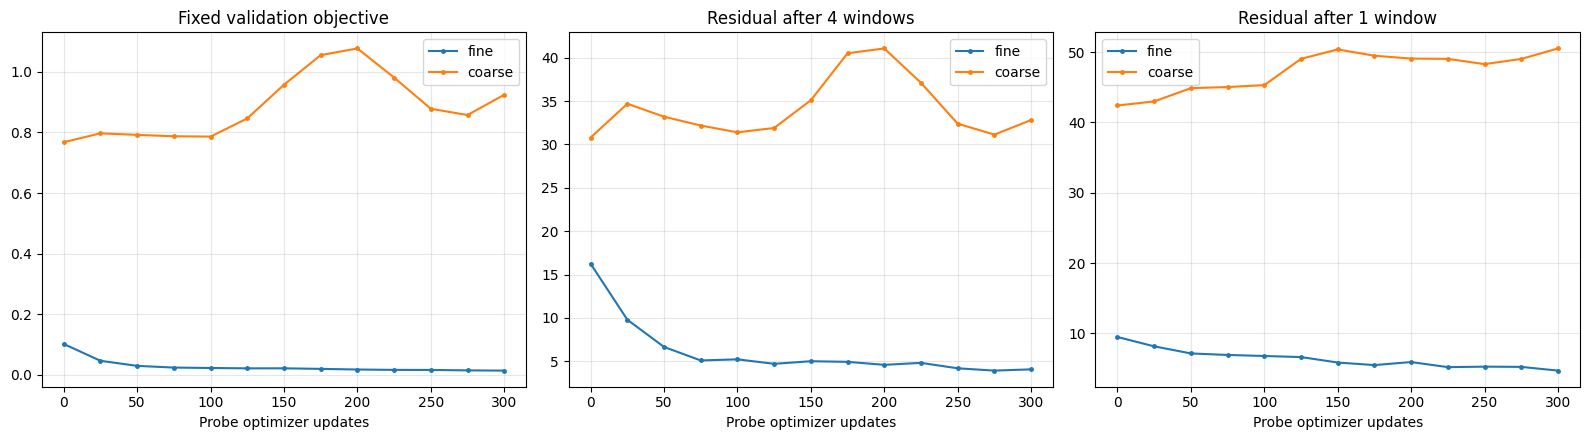

In [47]:
if STOCHASTIC_ROLLOUT_HISTORY:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    steps = [row['step'] for row in STOCHASTIC_ROLLOUT_HISTORY]
    for label in ('fine', 'coarse'):
        for metric, ax in (('loss_total', axes[0]), ('final_fault_residual_deg', axes[1]), ('one_step_fault_residual_deg', axes[2])):
            ax.plot(steps, [row[f'{label}/{metric}'] for row in STOCHASTIC_ROLLOUT_HISTORY], '-o', markersize=2.5, label=label)
    for ax, title in zip(axes, ('Fixed validation objective', 'Residual after 4 windows', 'Residual after 1 window')):
        ax.set(title=title, xlabel='Probe optimizer updates')
        ax.grid(alpha=0.3)
        ax.legend()
    fig.tight_layout()
    plt.show()


## 12. Full training: four-step batches and validation metrics

In [48]:
def run_rollout_epoch(loader, dataset, *, training: bool, generator, global_step: int):
    model.train(training)
    metric_sums, num_samples = {}, 0
    start_time = time.perf_counter()
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    for batch_number, indices in enumerate(loader):
        raw_steps = make_rollout_raw_windows(dataset, indices)
        physical_seed = int(torch.randint(0, 2**31 - 1, (1,), generator=generator, device=DEVICE).item())
        physical, initial_states, fault_masks, _ = prepare_rollout_case(raw_steps, physical_seed=physical_seed, fault_generator=generator)
        metrics = run_four_step_objective(physical, initial_states, fault_masks, training=training,
                                          active_optimizer=optimizer if training else None)
        batch_size = indices.shape[0]
        for key, value in metrics.items():
            # Avoid mixing the per-update norm (which can be NaN on validation) into aggregate metrics.
            if key == 'grad_norm_before_clip' and not training:
                continue
            if np.isfinite(value):
                metric_sums[key] = metric_sums.get(key, 0.0) + float(value) * batch_size
        num_samples += batch_size
        if training:
            global_step += 1
        if training and PRINT_EVERY_BATCHES > 0 and (batch_number + 1) % PRINT_EVERY_BATCHES == 0:
            print(f'batch {batch_number + 1}/{len(loader)} loss={metrics["loss_total"]:.3f} '
                  f'fault {metrics["initial_fault_deg"]:.1f}° → 1st {metrics["one_step_fault_residual_deg"]:.1f}° '
                  f'→ final {metrics["final_fault_residual_deg"]:.1f}° | '
                  f'geo={metrics["loss_rotation_geodesic"]:.3f} dir={metrics["loss_rotation_direction"]:.3f} '
                  f'mag={metrics["loss_rotation_magnitude"]:.3f}', flush=True)
        del raw_steps, physical, initial_states, fault_masks
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()
        torch.cuda.empty_cache()
    elapsed = time.perf_counter() - start_time
    if not num_samples:
        raise RuntimeError('No rollout groups in epoch')
    epoch_metrics = {name: val / num_samples for name, val in metric_sums.items()}
    epoch_metrics['epoch_time_s'] = elapsed
    epoch_metrics['trajectory_groups_per_second'] = num_samples / elapsed
    return epoch_metrics, global_step


## 13. Run directory, checkpoints, and resume

In [53]:
RUN_DIR = ROOT / 'runs' / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT_PATH = RUN_DIR / 'best.pt'
LAST_CHECKPOINT_PATH = RUN_DIR / 'last.pt'
METRICS_PATH = RUN_DIR / 'metrics.jsonl'
if INITIALIZATION_MODE == 'weights' and Path(INITIAL_WEIGHTS_CHECKPOINT).resolve() in (BEST_CHECKPOINT_PATH.resolve(), LAST_CHECKPOINT_PATH.resolve()):
    raise ValueError('Weights-only source cannot coincide with a new output checkpoint')
EXPERIMENT_SNAPSHOT = {
    'run_name': RUN_NAME, 'initialization_mode': INITIALIZATION_MODE,
    'initial_weights_checkpoint': str(INITIAL_WEIGHTS_CHECKPOINT) if INITIALIZATION_MODE == 'weights' else None,
    'rollout_steps': ROLLOUT_NUM_STEPS, 'detached_feedback': True, 'rotation_only_propagation': True,
    'update_all_sensor_keys': ROLLOUT_UPDATE_ALL_KEYS, 'fixed_initial_active_mask_weight': ROLLOUT_INITIAL_FAULT_WEIGHTING,
    'step_loss_weights': ROLLOUT_STEP_LOSS_WEIGHTS, 'selection_metric': ROLLOUT_SELECTION_METRIC,
    'start_stride_train': ROLLOUT_START_STRIDE_TRAIN, 'start_stride_val': ROLLOUT_START_STRIDE_VAL,
    'rotation_geodesic_weight': ROTATION_GEODESIC_WEIGHT, 'rotation_direction_weight': ROTATION_DIRECTION_WEIGHT,
    'rotation_magnitude_weight': ROTATION_MAGNITUDE_WEIGHT, 'active_rotation_weight': ACTIVE_ROTATION_WEIGHT,
    'healthy_rotation_weight': HEALTHY_ROTATION_WEIGHT, 'fine_max_deg': FINE_ROTATION_MAX_DEG,
    'coarse_min_deg': COARSE_ROTATION_MIN_DEG, 'coarse_max_deg': COARSE_ROTATION_MAX_DEG,
    'coarse_probability': COARSE_PRIOR_PROBABILITY, 'reference_tau_s': REFINED_TAU_BY_SENSOR_S,
    'true_calibration_augmentation': True, 'measurement_noise': False,
}
train_pair_generator = make_augmentation_generator(TRAIN_PAIR_SEED)
start_epoch, global_step, best_validation_loss = 0, 0, float('inf')
if INITIALIZATION_MODE == 'resume':
    checkpoint = load_training_checkpoint(RESUME_CHECKPOINT, model=model, optimizer=optimizer, scheduler=scheduler,
                                           map_location=DEVICE, restore_rng_state=True,
                                           generators={'train_shuffle': train_shuffle_generator, 'train_pair': train_pair_generator})
    start_epoch = int(checkpoint.get('epoch', 0))
    global_step = int(checkpoint.get('global_step', 0))
    best_validation_loss = float(checkpoint.get('extra_state', {}).get('best_validation_loss', float('inf')))
    print('Resumed complete four-step rollout state:', RESUME_CHECKPOINT, 'next epoch:', start_epoch + 1)
else:
    print('Fresh optimizer and scheduler; initial model:', INITIALIZATION_MODE)


Fresh optimizer and scheduler; initial model: weights


## 14. Full four-window training (independently controlled)
Validation uses exactly the same four-step initial-fault distribution as training. Its augmentation generator is restarted with the same seed each epoch. Best checkpoint is selected by final physical SO(3) residual, not combined direction/magnitude loss. All four per-step residuals are printed after each epoch.

In [54]:
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

In [55]:
history = []
if RUN_FULL_TRAINING and REQUIRE_STOCHASTIC_GATE and ROLLOUT_STOCHASTIC_GATE_PASSED is not True:
    raise RuntimeError('Required stochastic gate not passed')
if RUN_FULL_TRAINING:
    if INITIALIZATION_MODE != 'resume' and (BEST_CHECKPOINT_PATH.exists() or LAST_CHECKPOINT_PATH.exists()):
        raise FileExistsError(f'Output checkpoints already exist in {RUN_DIR}. Use a new run name or resume.')
    with MetricsLogger(METRICS_PATH, append=(INITIALIZATION_MODE == 'resume')) as logger:
        if INITIALIZATION_MODE != 'resume':
            logger.log_config(model_config, name='model_config')
            logger.log_config(context_augmentation_config, name='context_augmentation_config')
            logger.log_config(fine_prior_config, name='fine_prior_config')
            logger.log_config(coarse_prior_config, name='coarse_prior_config')
            logger.log_config({'learning_rate': LEARNING_RATE, 'batch_size_trajectories': BATCH_SIZE,
                               'train_sequences': TRAIN_NAMES, 'val_sequences': VAL_NAMES, **EXPERIMENT_SNAPSHOT}, name='experiment')
        for epoch in range(start_epoch, NUM_EPOCHS):
            train_metrics, global_step = run_rollout_epoch(rollout_train_loader, train_dataset, training=True, generator=train_pair_generator, global_step=global_step)
            val_metrics, _ = run_rollout_epoch(rollout_val_loader, val_dataset, training=False,
                                                generator=make_augmentation_generator(VALIDATION_PAIR_SEED), global_step=global_step)
            selection_value = val_metrics[ROLLOUT_SELECTION_METRIC]
            scheduler.step(selection_value)
            row = {'epoch': epoch + 1, 'global_step': global_step, 'learning_rate': optimizer.param_groups[0]['lr'],
                   **{f'train/{key}': value for key, value in train_metrics.items()},
                   **{f'val/{key}': value for key, value in val_metrics.items()}}
            history.append(row)
            logger.log_metrics({**train_metrics, 'learning_rate': optimizer.param_groups[0]['lr']}, split='train', epoch=epoch + 1, step=global_step)
            logger.log_metrics(val_metrics, split='validation', epoch=epoch + 1, step=global_step)
            for label, metrics in (('train', train_metrics), ('val', val_metrics)):
                residuals = [metrics[f'step{i}/fault_after_deg'] for i in range(1, 5)]
                print(f'Epoch {epoch + 1:3d}/{NUM_EPOCHS} {label:5s} | '
                      f'fault {metrics["initial_fault_deg"]:5.1f}° → '
                      + ' → '.join(f'{x:5.1f}°' for x in residuals)
                      + f' | total={metrics["loss_total"]:.4f} geo={metrics["loss_rotation_geodesic"]:.4f} '
                        f'dir={metrics["loss_rotation_direction"]:.4f} mag={metrics["loss_rotation_magnitude"]:.4f} '
                        f'healthy_final={metrics["final_healthy_error_deg"]:.1f}°', flush=True)
            print(f'LR={optimizer.param_groups[0]["lr"]:.3e} | selection val {ROLLOUT_SELECTION_METRIC}={selection_value:.3f}', flush=True)
            if selection_value < best_validation_loss:
                best_validation_loss = selection_value
                save_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler,
                                         epoch=epoch + 1, global_step=global_step, metrics=val_metrics,
                                         generators={'train_shuffle': train_shuffle_generator, 'train_pair': train_pair_generator},
                                         extra_state={'best_validation_loss': best_validation_loss, **EXPERIMENT_SNAPSHOT})
                print('Saved best checkpoint.')
            if (epoch + 1) % CHECKPOINT_EVERY_EPOCHS == 0 or (epoch + 1) == NUM_EPOCHS:
                save_training_checkpoint(LAST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler,
                                         epoch=epoch + 1, global_step=global_step, metrics=val_metrics,
                                         generators={'train_shuffle': train_shuffle_generator, 'train_pair': train_pair_generator},
                                         extra_state={'best_validation_loss': best_validation_loss, **EXPERIMENT_SNAPSHOT})
                print('Saved latest checkpoint.')
else:
    print('Full training disabled. Set RUN_FULL_TRAINING=True to train, with a fresh RUN_NAME.')


Epoch   1/100 train | fault  74.7° →  54.2° →  51.8° →  50.3° →  49.5° | total=2.6983 geo=1.3491 dir=0.5271 mag=0.8223 healthy_final=7.9°
Epoch   1/100 val   | fault  82.4° →  55.4° →  53.0° →  51.2° →  50.8° | total=2.7853 geo=1.3926 dir=0.5383 mag=0.9514 healthy_final=6.8°
LR=2.000e-05 | selection val final_fault_residual_deg=50.834
Saved best checkpoint.
Epoch   2/100 train | fault  69.2° →  50.5° →  48.4° →  47.9° →  47.8° | total=2.5179 geo=1.2589 dir=0.5777 mag=0.8231 healthy_final=6.7°
Epoch   2/100 val   | fault  82.4° →  55.9° →  53.8° →  52.4° →  51.7° | total=2.8058 geo=1.4029 dir=0.6007 mag=0.9796 healthy_final=6.5°
LR=2.000e-05 | selection val final_fault_residual_deg=51.678
Epoch   3/100 train | fault  72.4° →  51.1° →  48.8° →  47.8° →  47.7° | total=2.4698 geo=1.2349 dir=0.6117 mag=0.8318 healthy_final=6.4°
Epoch   3/100 val   | fault  82.4° →  56.2° →  53.9° →  52.2° →  52.0° | total=2.7816 geo=1.3908 dir=0.6235 mag=0.9683 healthy_final=6.8°
LR=2.000e-05 | selection va

KeyboardInterrupt: 

## 15. Training curves and independent held-out test

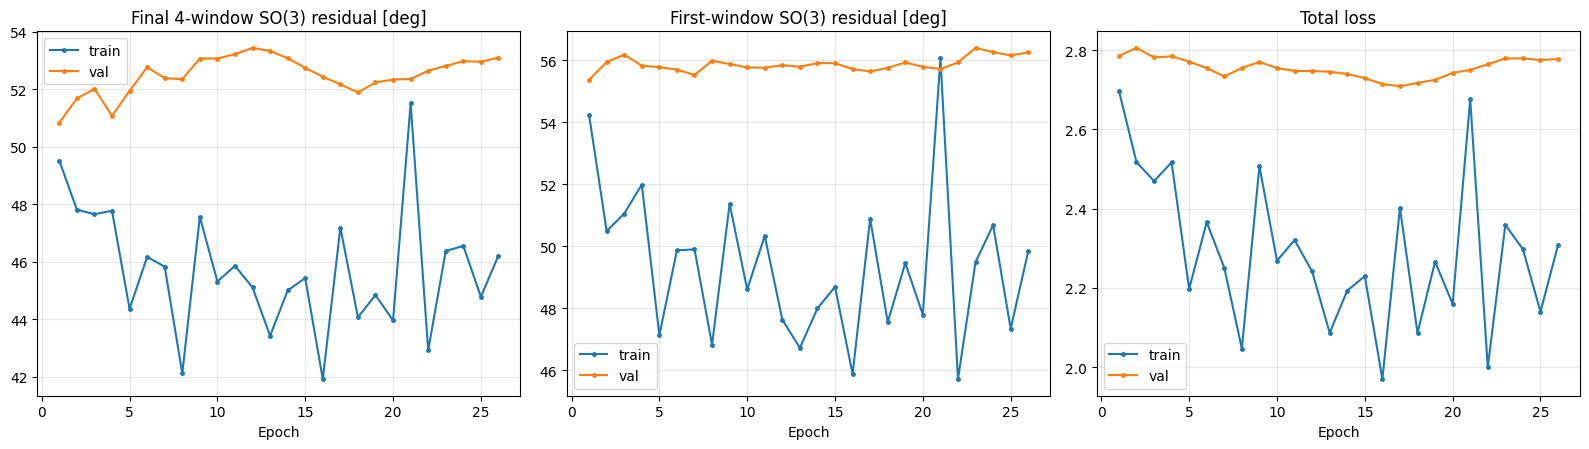

Evaluating best checkpoint, epoch: 1
TEST: initial / after 1 / after 2 / after 3 / after 4 [deg]: [72.59, 49.4, 47.5, 46.97, 45.77]
TEST losses: {'loss_total': 2.2526, 'loss_rotation_geodesic': 1.1263, 'loss_rotation_direction': 0.5282, 'loss_rotation_magnitude': 0.6864, 'final_healthy_error_deg': 6.2713}


In [56]:
if history:
    epochs = [row['epoch'] for row in history]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    for split in ('train', 'val'):
        axes[0].plot(epochs, [row[f'{split}/final_fault_residual_deg'] for row in history], '-o', markersize=2.5, label=split)
        axes[1].plot(epochs, [row[f'{split}/one_step_fault_residual_deg'] for row in history], '-o', markersize=2.5, label=split)
        axes[2].plot(epochs, [row[f'{split}/loss_total'] for row in history], '-o', markersize=2.5, label=split)
    for ax, label in zip(axes, ('Final 4-window SO(3) residual [deg]', 'First-window SO(3) residual [deg]', 'Total loss')):
        ax.set(title=label, xlabel='Epoch')
        ax.grid(alpha=0.3)
        ax.legend()
    fig.tight_layout()
    PLOT_DIR = RUN_DIR / 'plots'
    PLOT_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(PLOT_DIR / 'rollout_training_curves.png', dpi=160)
    plt.show()

if RUN_FULL_TRAINING and BEST_CHECKPOINT_PATH.exists():
    best_checkpoint = load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
    print('Evaluating best checkpoint, epoch:', best_checkpoint.get('epoch'))
    test_metrics, _ = run_rollout_epoch(rollout_test_loader, test_dataset, training=False,
                                        generator=make_augmentation_generator(TEST_PAIR_SEED), global_step=global_step)
    print('TEST: initial / after 1 / after 2 / after 3 / after 4 [deg]:',
          [round(test_metrics['initial_fault_deg'], 2)] + [round(test_metrics[f'step{i}/fault_after_deg'], 2) for i in range(1, 5)])
    print('TEST losses:', {key: round(test_metrics[key], 4) for key in
                           ('loss_total', 'loss_rotation_geodesic', 'loss_rotation_direction', 'loss_rotation_magnitude', 'final_healthy_error_deg')})


## 16. Optional exact-angle four-window evaluation
Evaluate the current in-memory model on held-out sequences with fixed initial angles and arbitrary axes (or X/Y/Z), feeding predictions into four chronological windows. This is an independent, rotation-only evaluation. By default it is disabled to avoid a lengthy scan. Set RUN_EXACT_ANGLE_EVALUATION=True to enable it.

/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Completed exact-angle four-window evaluation: Urban26
Completed exact-angle four-window evaluation: Urban28


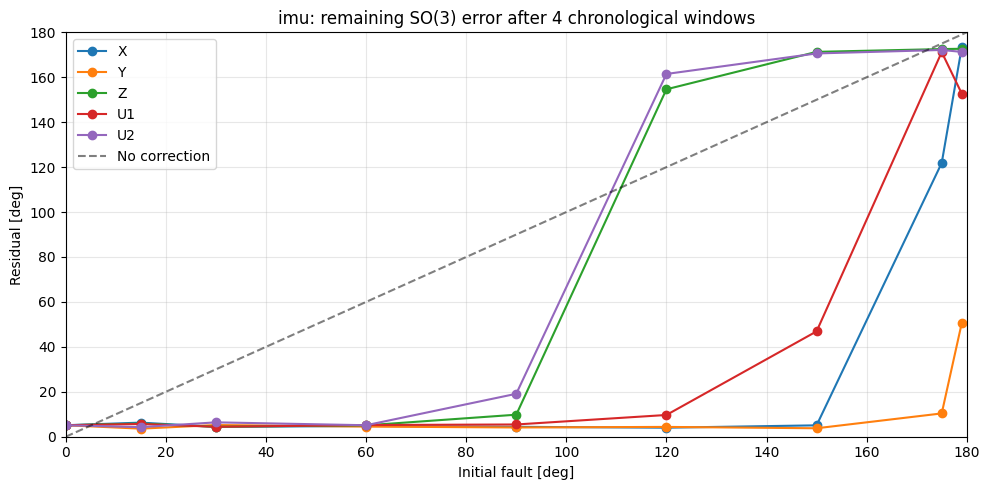

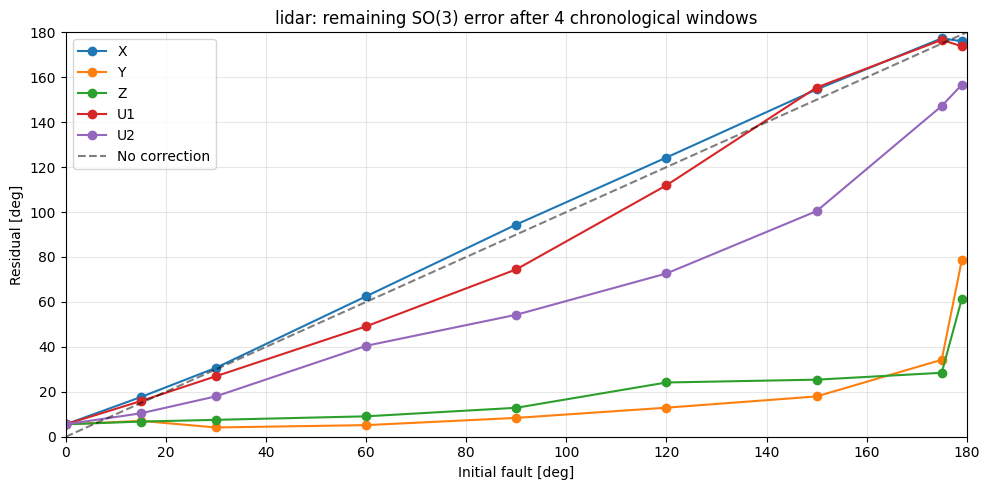

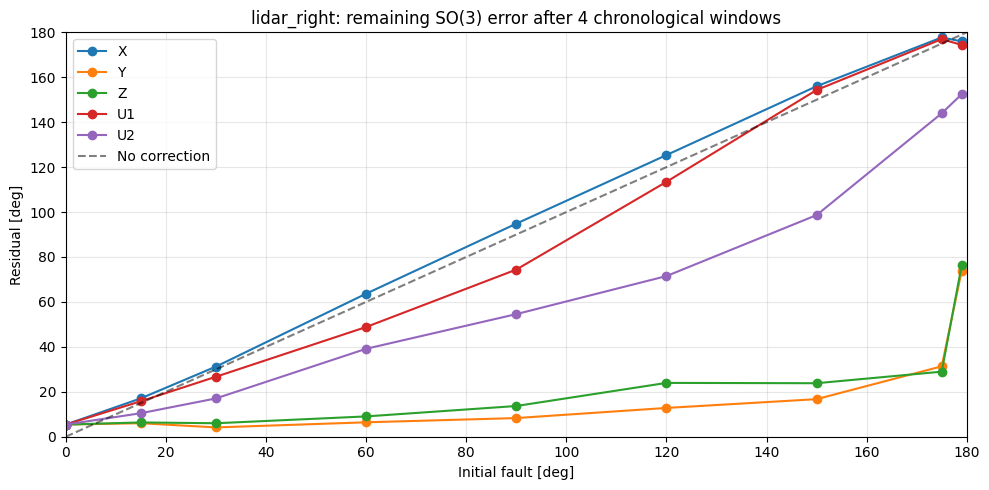

Saved four-window exact-angle evaluation under: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_large_paired_003.4_4step_rollout/plots/rollout67


In [58]:
RUN_EXACT_ANGLE_EVALUATION = True
EVAL67_SEQUENCE_NAMES = tuple(VAL_NAMES)
EVAL67_ANGLES_DEG = (0, 15, 30, 60, 90, 120, 150, 175, 179)
EVAL67_SENSOR_KEYS = CALIBRATION_KEYS
EVAL67_AXIS_NAMES = ('X', 'Y', 'Z', 'U1', 'U2')
EVAL67_GROUPS_PER_SEQUENCE = 2


def eval67_axes():
    axes = {'X': torch.tensor([1., 0., 0.], device=DEVICE, dtype=MODEL_DTYPE),
            'Y': torch.tensor([0., 1., 0.], device=DEVICE, dtype=MODEL_DTYPE),
            'Z': torch.tensor([0., 0., 1.], device=DEVICE, dtype=MODEL_DTYPE)}
    generator = make_augmentation_generator(670_711)
    for name in ('U1', 'U2'):
        x = torch.randn(3, generator=generator, device=DEVICE, dtype=MODEL_DTYPE)
        axes[name] = x / x.norm()
    return axes


@torch.no_grad()
def evaluate_exact_angle_four_steps():
    axes = eval67_axes()
    rows = []
    old_mode = model.training
    model.eval()
    try:
        for seq_name in EVAL67_SEQUENCE_NAMES:
            seq_starts = [tuple(map(int, val_dataset.window_indices_for_sequence(seq_name)[i:i + ROLLOUT_NUM_STEPS]))
                          for i in range(0, len(val_dataset.window_indices_for_sequence(seq_name)) - ROLLOUT_NUM_STEPS + 1, ROLLOUT_NUM_STEPS)]
            positions = np.unique(np.linspace(0, len(seq_starts) - 1, min(EVAL67_GROUPS_PER_SEQUENCE, len(seq_starts))).round().astype(int))
            for position in positions:
                raw = make_rollout_raw_windows(val_dataset, torch.tensor([seq_starts[int(position)]], dtype=torch.int64))
                physical_seed = 670_800 + int(position)
                physical = [context_augmentation_pipeline(window, generator=make_augmentation_generator(physical_seed)).augmented_window for window in raw]
                for t in range(1, ROLLOUT_NUM_STEPS):
                    for key in CALIBRATION_KEYS:
                        torch.testing.assert_close(physical[t].current_calibration[key].transform, physical[0].current_calibration[key].transform, atol=3e-5, rtol=3e-5)
                truth = physical[0].current_calibration
                for key in EVAL67_SENSOR_KEYS:
                    for axis_name in EVAL67_AXIS_NAMES:
                        for degrees in EVAL67_ANGLES_DEG:
                            fault_xi = {k: torch.zeros(1, 6, device=DEVICE, dtype=MODEL_DTYPE) for k in CALIBRATION_KEYS}
                            fault_tau = {k: torch.zeros(1, 1, device=DEVICE, dtype=MODEL_DTYPE) for k in CALIBRATION_KEYS}
                            fault_xi[key][:, :3] = np.deg2rad(degrees) * axes[axis_name]
                            initial_state = apply_prior_perturbation(truth, fault_xi, fault_tau)
                            mask = {k: torch.tensor([k == key], dtype=torch.bool, device=DEVICE) for k in CALIBRATION_KEYS}
                            states = copy_calibration_states(initial_state)
                            for step in range(ROLLOUT_NUM_STEPS + 1):
                                current_r = states[key].transform[:, :3, :3]
                                target_r = truth[key].transform[:, :3, :3]
                                relative = current_r @ target_r.transpose(-1, -2)
                                skew = torch.stack([relative[..., 2, 1] - relative[..., 1, 2], relative[..., 0, 2] - relative[..., 2, 0], relative[..., 1, 0] - relative[..., 0, 1]], dim=-1)
                                residual = torch.rad2deg(torch.atan2(0.5 * torch.linalg.vector_norm(skew, dim=-1), 0.5 * (relative.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1)))
                                rows.append({'sequence': seq_name, 'start_index': int(seq_starts[int(position)][0]), 'sensor': key,
                                             'axis': axis_name, 'initial_angle_deg': degrees, 'step': step, 'residual_deg': float(residual.item())})
                                if step < ROLLOUT_NUM_STEPS:
                                    predictions = window_step(clone_window_with_calibration(physical[step], states)).model_output.predictions
                                    states = apply_detached_rotation_feedback(states, predictions, mask)
            print('Completed exact-angle four-window evaluation:', seq_name, flush=True)
    finally:
        model.train(old_mode)
    return pd.DataFrame(rows)


if RUN_EXACT_ANGLE_EVALUATION:
    eval67_df = evaluate_exact_angle_four_steps()
    plot_dir = RUN_DIR / 'plots' / 'rollout67'
    plot_dir.mkdir(parents=True, exist_ok=True)
    eval67_df.to_csv(plot_dir / 'exact_angle_cases.csv', index=False)
    for key in EVAL67_SENSOR_KEYS:
        fig, ax = plt.subplots(figsize=(10, 5))
        for axis in EVAL67_AXIS_NAMES:
            sub = eval67_df[(eval67_df.sensor == key) & (eval67_df.axis == axis) & (eval67_df.step == ROLLOUT_NUM_STEPS)]
            curve = sub.groupby('initial_angle_deg', as_index=False).residual_deg.mean()
            ax.plot(curve.initial_angle_deg, curve.residual_deg, '-o', label=axis)
        ax.plot([0, 180], [0, 180], 'k--', alpha=0.5, label='No correction')
        ax.set(title=f'{key}: remaining SO(3) error after 4 chronological windows', xlabel='Initial fault [deg]', ylabel='Residual [deg]', xlim=(0, 180), ylim=(0, 180))
        ax.grid(alpha=0.3)
        ax.legend()
        fig.tight_layout()
        fig.savefig(plot_dir / f'{key}_exact_angle.png', dpi=160)
        plt.show()
    print('Saved four-window exact-angle evaluation under:', plot_dir)


## Interpretation and checks
- Four chronological windows must use exactly the same physical extrinsic truth. The augmentation assertions intentionally stop execution if they do not.
- No gradient through calibration-state propagation: this is detached feedback, not full differentiable BPTT.
- The model predicts a correction at each window and incurs supervised loss at each window; no explicit path, consistency or progress term.
- ROLLOUT_UPDATE_ALL_KEYS=True models correction of all three sensors and exposes healthy-sensor drift; set False to reproduce the earlier one-fault-sensor-only rollout behavior.
- The mixed prior's Student-t fine range includes small-angle errors but does not guarantee an exact 0° case for the initially faulted sensor. The other two sensors start exactly calibrated in each sampled example, so they provide healthy-sensor anchors.
- A four-step final residual can improve simply because corrections are iterated; compare against the initial model on identical fixed probes and monitor the change during training.
- The stochastic test restores weights. Enable full training explicitly afterward, and use a new RUN_NAME for every weights-only experiment.